# Griffiths et al. 2021 — Breast Cancer · 03 Signatures & Gate 2
Read the embryonic-module geography off the signature embeddings (raw `score_genes`) and the smoothed-score relationships.

**Gate 2** — is the pattern present? Either (a) a Gast/pSom hub diverging into **two arms** with Crest high at the tips (branching), or (b) a single **(Gast/pSom)→Crest** developmental gradient with organized cross-repression and a terminal Crest gradient (non-branching). Both **pass (GO)**; only the non-branching case has no bifurcation for Gate 3 (NA). Flag (pass anyway) if Crest enriches the Gast arm.

In [1]:
%matplotlib inline
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Griffiths2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast
dataset = 'Data_Griffiths2021_Breast'                    # on-disk input (no -N suffix)
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', dataset)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| module scores present:',
      [m for m in ['Gast','pSom','Crest'] if m in adata.obs])

cells: 108658 | module scores present: ['Gast', 'pSom', 'Crest']


### Gate 2 — module geography
Read the geography off the smoothed relationships and the raw signature embeddings. A branching outcome shows Gast and pSom diverging into two arms; a non-branching outcome shows them co-located / inversely graded against a terminal Crest readout.

In [4]:
print('smoothed geography correlations:')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.3f}')
print('raw pSom vs Crest: %+.3f' % np.corrcoef(adata.obs.pSom, adata.obs.Crest)[0,1])
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
for l in ['Gast','pSom','Crest']:
    print(f'  {l}-high decile mean pseudotime = {tn[adata.obs[l].values >= np.quantile(adata.obs[l],0.9)].mean():.3f}')
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

smoothed geography correlations:
  Gast_sm vs pSom_sm: r = -0.381
  Crest_sm vs Gast_sm: r = -0.238
  Crest_sm vs pSom_sm: r = -0.720
raw pSom vs Crest: -0.532
  Gast-high decile mean pseudotime = 0.491
  pSom-high decile mean pseudotime = 0.404
  Crest-high decile mean pseudotime = 0.483
raw module means: {'Gast': -0.0194, 'pSom': -0.053, 'Crest': 0.0228}


**Gate 2 → GO (non-branching).** The embryonic programs are present and organized: smoothed **pSom↔Crest r ≈ −0.7** and Gast↔pSom r ≈ −0.4 — pSom and Crest occupy opposite territories on one continuous manifold (a single inverse/terminal gradient), **not** two diverging arms. No Gast/pSom hub bifurcates → **Gate 3 NA**. Crest does not preferentially enrich a Gast arm (no arm inversion to flag). This matches the linear outcome seen across the other CCCA breast datasets.

### Figures — signature embeddings (raw scores) + external colorbars

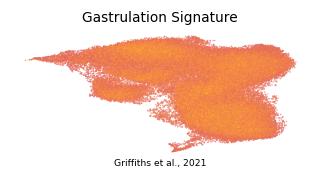

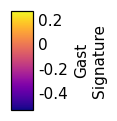

In [5]:
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='Gast', cmap='plasma', alpha=.6, size=4, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
ax.set_title('Gastrulation Signature', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'Gast_signature.pdf'), bbox_inches='tight')
# external colorbar
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature'); cb.set_ticks([-.4,-.2,0,.2], labels=[-.4,-.2,0,.2]); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches='tight')

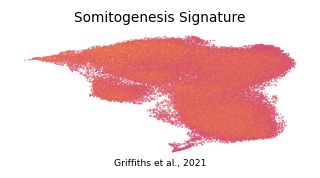

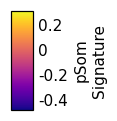

In [6]:
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='pSom', cmap='plasma', alpha=.6, size=4, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
ax.set_title('Somitogenesis Signature', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'pSom_signature.pdf'), bbox_inches='tight')
# external colorbar
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature'); cb.set_ticks([-.4,-.2,0,.2], labels=[-.4,-.2,0,.2]); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches='tight')

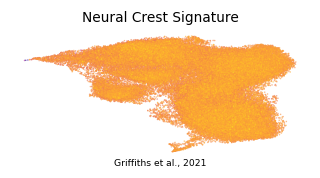

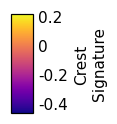

In [7]:
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='Crest', cmap='plasma', alpha=.6, size=4, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
ax.set_title('Neural Crest Signature', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'Crest_signature.pdf'), bbox_inches='tight')
# external colorbar
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature'); cb.set_ticks([-.4,-.2,0,.2], labels=[-.4,-.2,0,.2]); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches='tight')

In [8]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (108658, 21250)
